# 02 方案 B：IP-Adapter（參考圖約束角色外觀）

方案 A 只靠文字描述外觀，人類角色的臉每格都不同。方案 B 先為每篇主角生成一張參考圖，再用 IP-Adapter 把參考圖的 image embedding 注入 cross-attention，讓 6 格都參照同一個角色。

**執行前**：「執行階段 → 變更執行階段類型」選 **T4 GPU**。

**步驟**
1. 生成主角參考圖候選（每篇 `N_REF` 張正面全身立繪）
2. **人工挑選**每篇的參考圖（填 `REF_CHOICE`）
3. 載入 IP-Adapter（`h94/IP-Adapter` 的 `ip-adapter-plus_sdxl_vit-h`）
4. scale 掃描：在 `SCAN_STORIES` 上比較 `SCALES`，與方案 A 並排
5. 選定 `BEST_SCALE`，跑完 5 篇 30 格
6. 方案 A／B 並排比較

**設計**
- 只對主角（`characters[0]`）用參考圖；故事 3 的小貓仍只靠 prompt（範圍以單一主角為底線）
- seed、prompt、生圖參數都與方案 A 相同，差異只來自 IP-Adapter
- 參考圖用中性站姿、白背景，降低 IP-Adapter 照抄參考圖姿勢與構圖的傾向
- 輸出：`outputs/render/refs/`（參考圖候選）、`outputs/render/B_s{scale}/`（各 scale 的結果）

In [1]:
# ==== 設定 ====
REPO_URL = "https://github.com/77JoyWang77/1151-AI-Final.git"
REPO_DIR = "/content/1151-AI-Final"
DRIVE_ROOT = "/content/drive/MyDrive/1151-AI-Final"  # 生成結果存這裡
STORIES = [1, 2, 3, 4, 5]
N_REF = 4                  # 每個主角的參考圖候選數
SCALES = [0.3, 0.5, 0.7]   # IP-Adapter scale 掃描
SCAN_STORIES = [1, 3]      # 掃描用：方案 A 一致性最差的兩篇（多色外觀的人類）
CPU_OFFLOAD = False        # 若出現 CUDA out of memory 改成 True（較慢）

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### 取得程式碼

repo 目前是 public，不用設定。若改成 **private**：左側欄「鑰匙」圖示（Secrets）新增 `GH_TOKEN`，值為 GitHub personal access token（只需 repo 讀取權限），並開啟「Notebook access」。

若重啟過執行階段（`/content` 會被清空），要從第一格重新執行。

In [2]:
import base64
import os
import subprocess


def clone(*git_opts):
    return subprocess.run(["git", *git_opts, "clone", "-q", REPO_URL, REPO_DIR], capture_output=True, text=True)


if os.path.isdir(f"{REPO_DIR}/.git"):
    !git -C {REPO_DIR} pull -q --ff-only
else:
    !rm -rf {REPO_DIR}  # 清掉上次 clone 失敗留下的殘骸
    result = clone()  # public repo 不需要 token
    if result.returncode != 0:
        try:
            from google.colab import userdata
            token = (userdata.get("GH_TOKEN") or "").strip()
        except Exception:
            token = ""
        # 不印出 token 內容；檢查前綴，避免誤填成 OpenAI key 等其他密鑰
        if not token.startswith(("ghp_", "github_pat_")):
            raise RuntimeError("clone 失敗，且 Secrets 沒有有效的 GH_TOKEN（GitHub token 以 ghp_ 或 github_pat_ 開頭）\n"
                               + result.stderr)
        # token 放在 HTTP header 而不是網址，git 的錯誤訊息不會把它印出來
        auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
        result = clone("-c", f"http.extraHeader=Authorization: Basic {auth}")
        if result.returncode != 0:
            raise RuntimeError("用 GH_TOKEN clone 仍失敗：\n" + result.stderr)
assert os.path.isdir(f"{REPO_DIR}/src/comic_agent"), "clone 失敗：src/comic_agent 不存在"
!git -C {REPO_DIR} log --oneline -1

83bc535 (HEAD -> main, origin/main, origin/HEAD) Add scheme B (IP-Adapter) notebook; share cells across notebooks


In [3]:
!pip install -q diffusers transformers accelerate python-dotenv

In [4]:
import importlib
import json
import subprocess
import sys
import time

if f"{REPO_DIR}/src" not in sys.path:
    sys.path.insert(0, f"{REPO_DIR}/src")
importlib.invalidate_caches()  # 同一個 kernel 若在 clone 前 import 失敗過，Python 會記住「路徑不存在」
from comic_agent import render

CONFIG = render.GenConfig()
OUT_ROOT = f"{DRIVE_ROOT}/outputs/render"
GIT_COMMIT = subprocess.check_output(["git", "-C", REPO_DIR, "rev-parse", "--short", "HEAD"], text=True).strip()

boards = render.load_frozen_storyboards(f"{REPO_DIR}/data/storyboards")

ref_jobs = [r for r in render.reference_jobs(boards, N_REF) if r["story_no"] in STORIES]
print(CONFIG)
print(f"參考圖候選 {len(ref_jobs)} 張，commit {GIT_COMMIT}，輸出到 {OUT_ROOT}")

GenConfig(model_id='stabilityai/stable-diffusion-xl-base-1.0', vae_id='madebyollin/sdxl-vae-fp16-fix', scheduler='DPM++ 2M Karras', steps=30, cfg=6.5, width=1024, height=1024)
參考圖候選 20 張，commit 83bc535，輸出到 /content/drive/MyDrive/1151-AI-Final/outputs/render


### 載入 SDXL

第一次執行會下載約 7 GB 權重，需要幾分鐘。VAE 換成 `sdxl-vae-fp16-fix`，原版 VAE 在 fp16 下會溢位產生黑圖。

In [5]:
import torch
from diffusers import AutoencoderKL, DPMSolverMultistepScheduler, StableDiffusionXLPipeline

vae = AutoencoderKL.from_pretrained(CONFIG.vae_id, dtype=torch.float16)
pipe = StableDiffusionXLPipeline.from_pretrained(
    CONFIG.model_id, vae=vae, dtype=torch.float16, variant="fp16", use_safetensors=True,
)
# DPM++ 2M Karras
pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe.scheduler.config, algorithm_type="dpmsolver++", solver_order=2, use_karras_sigmas=True,
)
if CPU_OFFLOAD:
    pipe.enable_model_cpu_offload()
else:
    pipe.to("cuda")
pipe.set_progress_bar_config(disable=True)
print(torch.cuda.get_device_name(0), f"{torch.cuda.memory_allocated() / 2**30:.1f} GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

...

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Tesla T4 6.6 GB


In [6]:
from pathlib import Path

from PIL import Image, ImageDraw


def generate(job, out_root=OUT_ROOT, skip_existing=True, pipe_kwargs=None, record=None):
    """生成一格並存圖與紀錄；已存在且設定相同就略過（斷線續跑）。

    「設定」= prompt 加上 record 的欄位（例如 IP-Adapter scale、參考圖）。
    任一項改變（例如換了畫風或參考圖）都會重新生成並覆蓋，避免沿用舊圖。
    """
    record = record or {}
    png, js = render.panel_paths(out_root, job)
    if skip_existing and png.exists() and js.exists():
        old = json.loads(js.read_text(encoding="utf-8"))
        if all(old.get(k) == v for k, v in {"prompt": job["prompt"], **record}.items()):
            return png, False
    generator = torch.Generator("cpu").manual_seed(job["seed"])  # CPU generator：跨機器較可重現
    t0 = time.time()
    image = pipe(
        prompt=job["prompt"],
        negative_prompt=job["negative_prompt"],
        num_inference_steps=CONFIG.steps,
        guidance_scale=CONFIG.cfg,
        width=CONFIG.width,
        height=CONFIG.height,
        generator=generator,
        **(pipe_kwargs or {}),
    ).images[0]
    seconds = round(time.time() - t0, 1)
    png.parent.mkdir(parents=True, exist_ok=True)
    image.save(png)
    render.write_record(js, job, CONFIG, seconds=seconds, git_commit=GIT_COMMIT,
                        gpu=torch.cuda.get_device_name(0), **record)
    return png, True


def contact_sheet(pngs, cols=3, thumb=384, labels=None):
    """把多張圖排成總覽圖；labels 為每一列的標題。缺圖的位置留白。"""
    rows = (len(pngs) + cols - 1) // cols
    head = 28 if labels else 0
    sheet = Image.new("RGB", (thumb * cols, (thumb + head) * rows), "white")
    draw = ImageDraw.Draw(sheet)
    for i, p in enumerate(pngs):
        r, c = divmod(i, cols)
        if p is not None and Path(p).exists():
            sheet.paste(Image.open(p).resize((thumb, thumb)), (c * thumb, r * (thumb + head) + head))
    for r, text in enumerate(labels or []):
        draw.text((6, r * (thumb + head) + 6), text, fill="black")
    return sheet

### 1. 生成主角參考圖候選

每篇 `N_REF` 張，約 25 秒一張（5 篇 × 4 張 ≈ 8 分鐘）。**必須在載入 IP-Adapter 之前執行**：載入後每次生圖都需要參考圖。若之後要補生參考圖，請重啟執行階段再從頭跑（已生成的會略過）。

[1/20] story 1 候選 #1：生成
[2/20] story 1 候選 #2：生成
[3/20] story 1 候選 #3：生成
[4/20] story 1 候選 #4：生成
[5/20] story 2 候選 #1：生成
[6/20] story 2 候選 #2：生成
[7/20] story 2 候選 #3：生成
[8/20] story 2 候選 #4：生成
[9/20] story 3 候選 #1：生成
[10/20] story 3 候選 #2：生成
[11/20] story 3 候選 #3：生成
[12/20] story 3 候選 #4：生成
[13/20] story 4 候選 #1：生成
[14/20] story 4 候選 #2：生成
[15/20] story 4 候選 #3：生成
[16/20] story 4 候選 #4：生成
[17/20] story 5 候選 #1：生成
[18/20] story 5 候選 #2：生成
[19/20] story 5 候選 #3：生成
[20/20] story 5 候選 #4：生成

story 1 主角 lily：young girl, curly brown hair, pink sun hat, blue swimsuit, yellow sandals


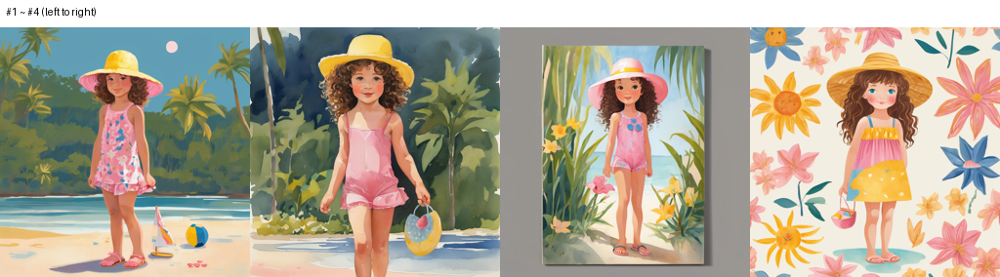


story 2 主角 bear：brown bear, round face, small ears, red scarf, blue overalls


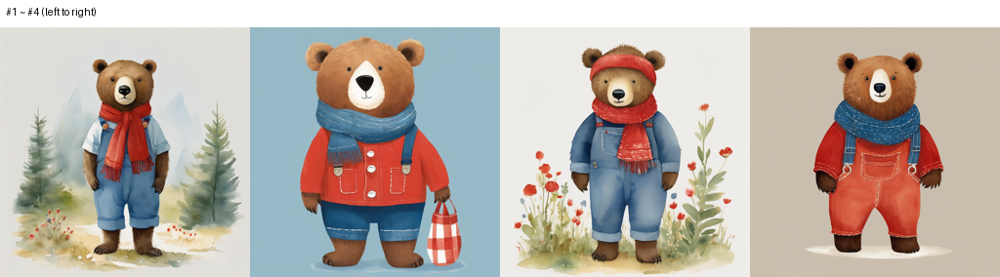


story 3 主角 boy：young boy, short brown hair, blue raincoat, yellow rain boots, small backpack


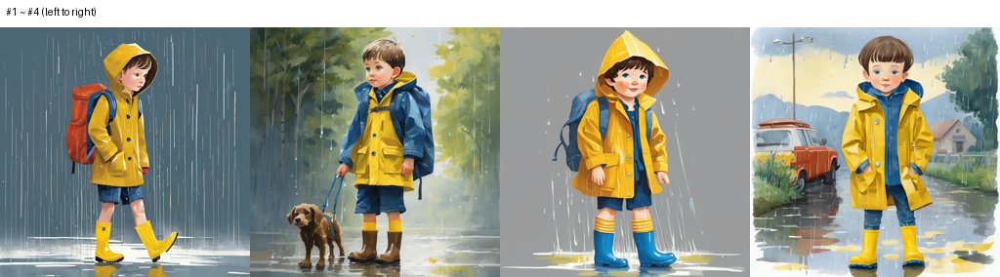


story 4 主角 fox：orange fox, white belly, big eyes, little paws, red scarf, bushy tail, small ears


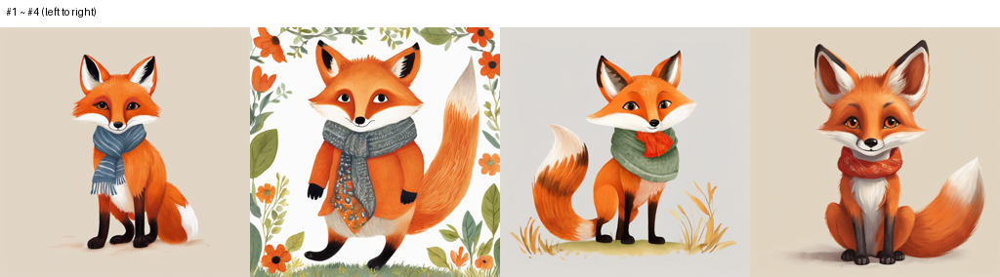


story 5 主角 girl：young girl, curly brown hair, pink pajamas, red slippers, small necklace


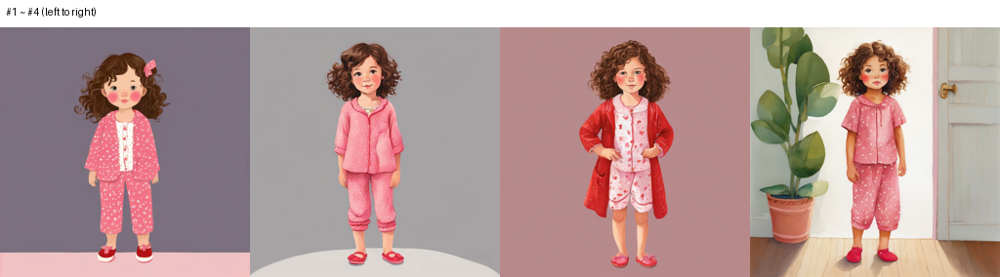

In [7]:
for k, job in enumerate(ref_jobs, 1):
    _, new = generate(job)
    print(f"[{k}/{len(ref_jobs)}] story {job['story_no']} 候選 #{job['panel_index']}：{'生成' if new else '已存在，略過'}")

for story_no in STORIES:
    hero = render.protagonist(boards[story_no])
    cands = [render.panel_paths(OUT_ROOT, j)[0] for j in ref_jobs if j["story_no"] == story_no]
    print(f"\nstory {story_no} 主角 {hero['id']}：{hero['appearance']}")
    display(contact_sheet(cands, cols=N_REF, thumb=256, labels=["#1 ~ #%d (left to right)" % N_REF]))

### 2. 挑選參考圖

每篇填一個候選編號（由左至右 1 開始）。挑選原則：
- 外觀符合描述（髮型、服裝、配色都對）
- 正面、全身、背景乾淨、只有一個角色
- 姿勢中性（越特殊的姿勢越容易被照抄到每一格）

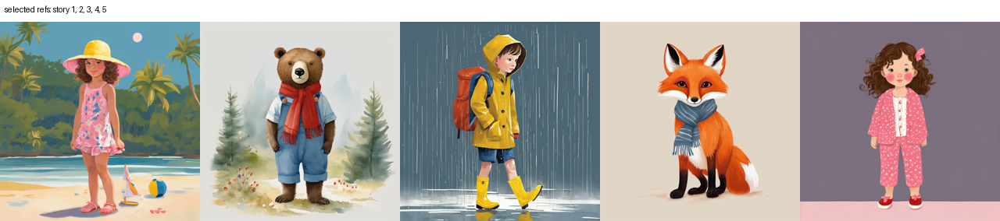

In [8]:
REF_CHOICE = {1: 1, 2: 1, 3: 1, 4: 1, 5: 1}  # 故事編號 → 候選編號

ref_paths = {}
for story_no in STORIES:
    job = next(j for j in ref_jobs if j["story_no"] == story_no and j["panel_index"] == REF_CHOICE[story_no])
    ref_paths[story_no] = render.panel_paths(OUT_ROOT, job)[0]
(Path(OUT_ROOT) / "refs" / "choice.json").write_text(
    json.dumps({str(s): REF_CHOICE[s] for s in STORIES}, indent=2), encoding="utf-8")
display(contact_sheet(list(ref_paths.values()), cols=len(ref_paths), thumb=256,
                      labels=["selected refs: story " + ", ".join(map(str, STORIES))]))

### 3. 載入 IP-Adapter

`plus` 版保留較多服裝與配色細節；image encoder 是 ViT-H（`models/image_encoder`），與 SDXL 資料夾內預設的 ViT-bigG 不同，要明確指定。

In [9]:
IP_REPO, IP_SUBFOLDER, IP_WEIGHT = "h94/IP-Adapter", "sdxl_models", "ip-adapter-plus_sdxl_vit-h.safetensors"
pipe.load_ip_adapter(IP_REPO, subfolder=IP_SUBFOLDER, weight_name=IP_WEIGHT,
                     image_encoder_folder="models/image_encoder")
print("IP-Adapter 已載入", f"{torch.cuda.memory_allocated() / 2**30:.1f} GB")


def run_scheme_b(scale, stories):
    """以指定 scale 生成方案 B；結果存在 B_s{scale}/，換參考圖或 scale 會自動重生。"""
    pipe.set_ip_adapter_scale(scale)
    scheme = f"B_s{scale}"
    todo = [j for j in render.iter_jobs(boards, scheme) if j["story_no"] in stories]
    for k, job in enumerate(todo, 1):
        ref = ref_paths[job["story_no"]]
        _, new = generate(
            job,
            pipe_kwargs={"ip_adapter_image": Image.open(ref).convert("RGB")},
            record={"ip_adapter": IP_WEIGHT, "ip_scale": scale,
                    "ref_image": f"refs/story_{job['story_no']}/{ref.name}"},
        )
        print(f"[{scheme} {k}/{len(todo)}] story {job['story_no']} panel {job['panel_index']}："
              f"{'生成' if new else '已存在，略過'}")
    return scheme


def compare(story_no, schemes):
    """每列一個方案、每欄一格，與參考圖一起顯示。"""
    n = len(boards[story_no]["panels"])
    pngs = [render.panel_paths(OUT_ROOT, {"scheme": s, "story_no": story_no, "panel_index": i})[0]
            for s in schemes for i in range(1, n + 1)]
    print(f"story {story_no}《{boards[story_no]['title']}》 參考圖：")
    display(Image.open(ref_paths[story_no]).resize((192, 192)))
    sheet = contact_sheet(pngs, cols=n, thumb=256, labels=list(schemes))
    sheet.save(Path(OUT_ROOT) / f"compare_story_{story_no}.png")
    display(sheet)

sdxl_models/ip-adapter-plus_sdxl_vit-h.s(…): reconstructing file:   0%|          |  0.00B /  848MB            

sdxl_models/ip-adapter-plus_sdxl_vit-h.s(…): downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/560 [00:00<?, ?B/s]

models/image_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B / 2.53GB            

models/image_encoder/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


IP-Adapter 已載入 8.5 GB


### 4. scale 掃描

scale 越高越像參考圖，但越容易壓過 prompt（動作、場景不符）或照抄參考圖姿勢。2 篇 × 6 格 × 3 個 scale ≈ 16 分鐘。看並排圖時注意：
- 臉、髮型、服裝是否跨格一致（一致性）
- 每格的動作與場景是否還符合分鏡（圖文對齊）
- 是否每格都是參考圖的站姿（copy-paste）

[B_s0.3 1/12] story 1 panel 1：生成
[B_s0.3 2/12] story 1 panel 2：生成
[B_s0.3 3/12] story 1 panel 3：生成
[B_s0.3 4/12] story 1 panel 4：生成
[B_s0.3 5/12] story 1 panel 5：生成
[B_s0.3 6/12] story 1 panel 6：生成
[B_s0.3 7/12] story 3 panel 1：生成
[B_s0.3 8/12] story 3 panel 2：生成
[B_s0.3 9/12] story 3 panel 3：生成
[B_s0.3 10/12] story 3 panel 4：生成
[B_s0.3 11/12] story 3 panel 5：生成
[B_s0.3 12/12] story 3 panel 6：生成
[B_s0.5 1/12] story 1 panel 1：生成
[B_s0.5 2/12] story 1 panel 2：生成
[B_s0.5 3/12] story 1 panel 3：生成
[B_s0.5 4/12] story 1 panel 4：生成
[B_s0.5 5/12] story 1 panel 5：生成
[B_s0.5 6/12] story 1 panel 6：生成
[B_s0.5 7/12] story 3 panel 1：生成
[B_s0.5 8/12] story 3 panel 2：生成
[B_s0.5 9/12] story 3 panel 3：生成
[B_s0.5 10/12] story 3 panel 4：生成
[B_s0.5 11/12] story 3 panel 5：生成
[B_s0.5 12/12] story 3 panel 6：生成
[B_s0.7 1/12] story 1 panel 1：生成
[B_s0.7 2/12] story 1 panel 2：生成
[B_s0.7 3/12] story 1 panel 3：生成
[B_s0.7 4/12] story 1 panel 4：生成
[B_s0.7 5/12] story 1 panel 5：生成
[B_s0.7 6/12] story 1 panel 6：生成
[B_s

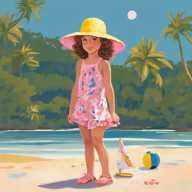

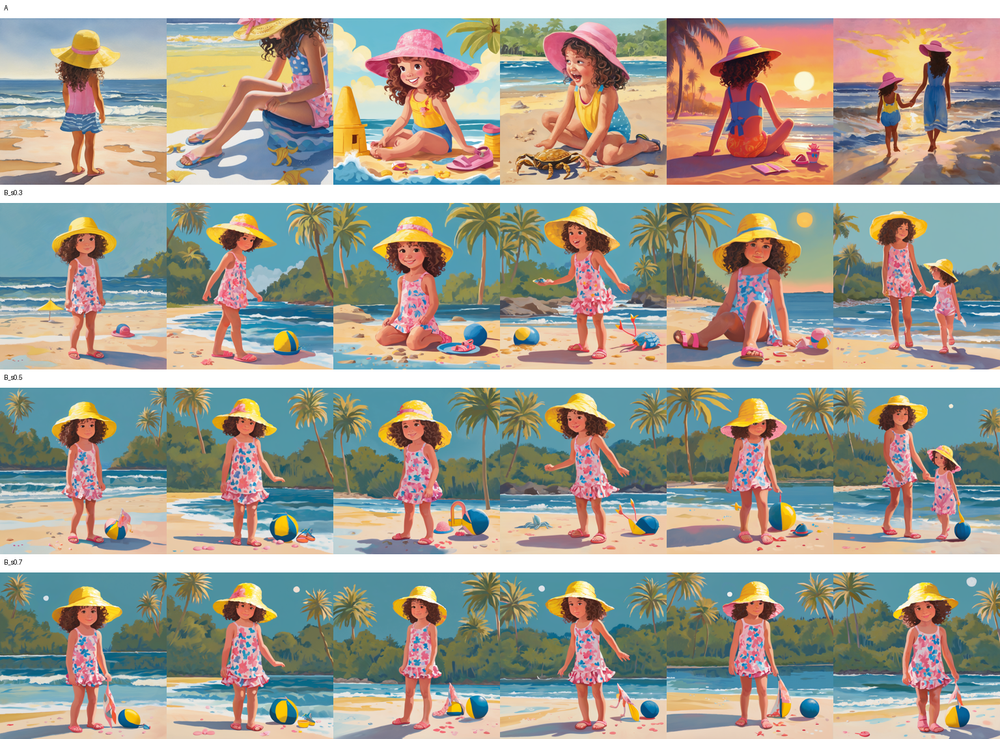

story 3《雨天裡的溫暖小幫手》 參考圖：


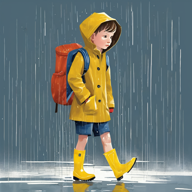

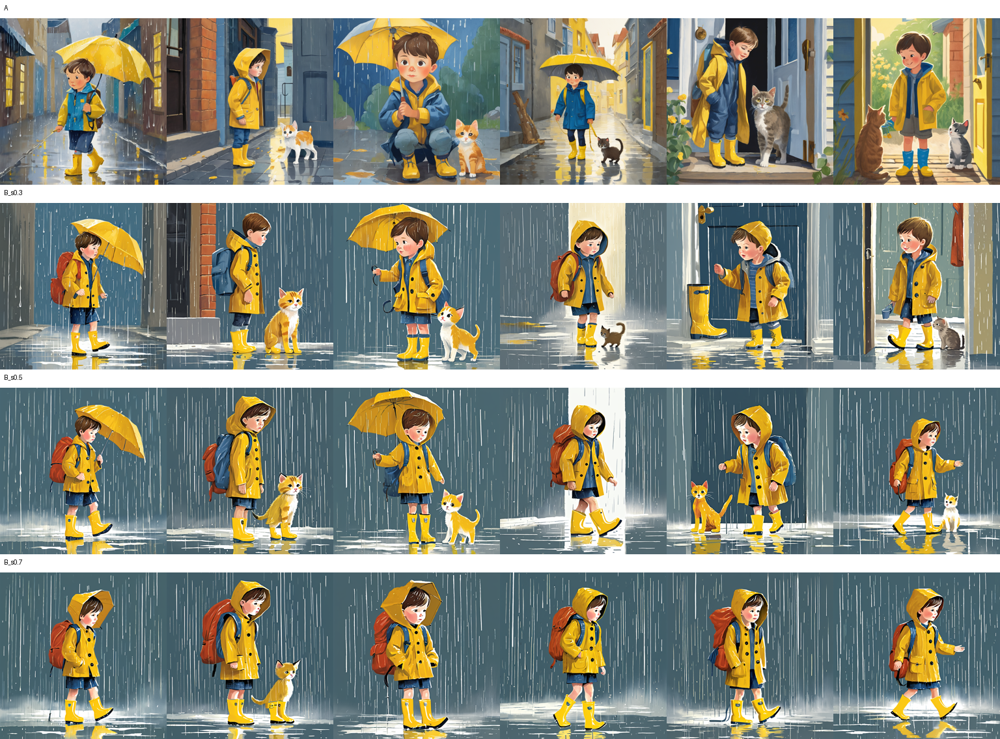

In [10]:
for scale in SCALES:
    run_scheme_b(scale, SCAN_STORIES)
for story_no in SCAN_STORIES:
    compare(story_no, ["A"] + [f"B_s{s}" for s in SCALES])

### 5. 以選定的 scale 跑完 5 篇

掃描用過的故事會直接沿用，不會重生。

[B_s0.5 1/30] story 1 panel 1：已存在，略過
[B_s0.5 2/30] story 1 panel 2：已存在，略過
[B_s0.5 3/30] story 1 panel 3：已存在，略過
[B_s0.5 4/30] story 1 panel 4：已存在，略過
[B_s0.5 5/30] story 1 panel 5：已存在，略過
[B_s0.5 6/30] story 1 panel 6：已存在，略過
[B_s0.5 7/30] story 2 panel 1：生成
[B_s0.5 8/30] story 2 panel 2：生成
[B_s0.5 9/30] story 2 panel 3：生成
[B_s0.5 10/30] story 2 panel 4：生成
[B_s0.5 11/30] story 2 panel 5：生成
[B_s0.5 12/30] story 2 panel 6：生成
[B_s0.5 13/30] story 3 panel 1：已存在，略過
[B_s0.5 14/30] story 3 panel 2：已存在，略過
[B_s0.5 15/30] story 3 panel 3：已存在，略過
[B_s0.5 16/30] story 3 panel 4：已存在，略過
[B_s0.5 17/30] story 3 panel 5：已存在，略過
[B_s0.5 18/30] story 3 panel 6：已存在，略過
[B_s0.5 19/30] story 4 panel 1：生成
[B_s0.5 20/30] story 4 panel 2：生成
[B_s0.5 21/30] story 4 panel 3：生成
[B_s0.5 22/30] story 4 panel 4：生成
[B_s0.5 23/30] story 4 panel 5：生成
[B_s0.5 24/30] story 4 panel 6：生成
[B_s0.5 25/30] story 5 panel 1：生成
[B_s0.5 26/30] story 5 panel 2：生成
[B_s0.5 27/30] story 5 panel 3：生成
[B_s0.5 28/30] story 5 panel 4：生成
[B_s0.5 2

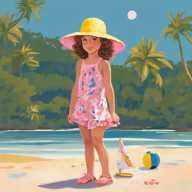

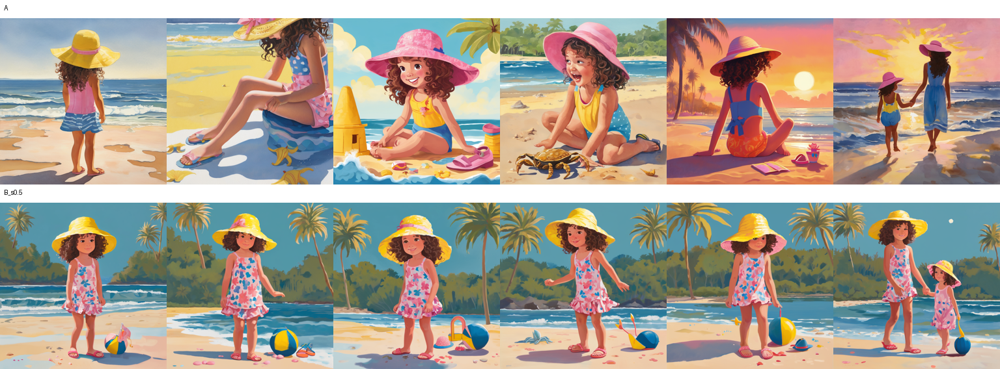

story 2《小熊找回遺失的帽子》 參考圖：


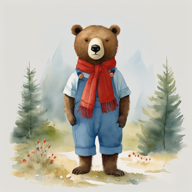

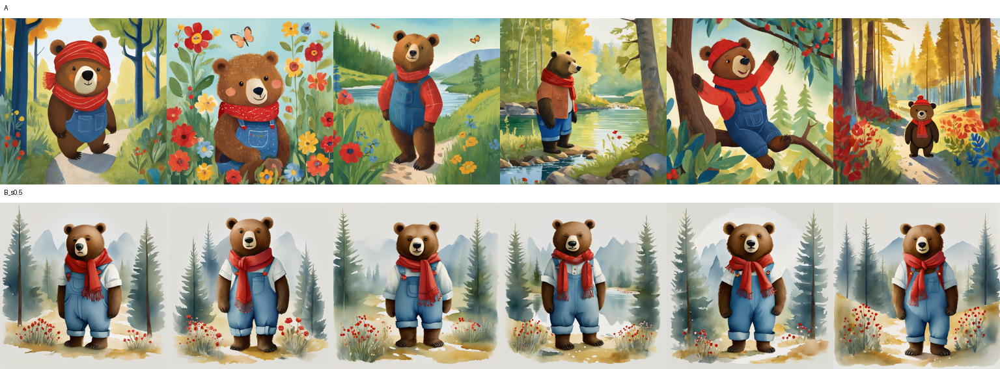

story 3《雨天裡的溫暖小幫手》 參考圖：


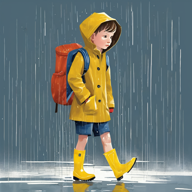

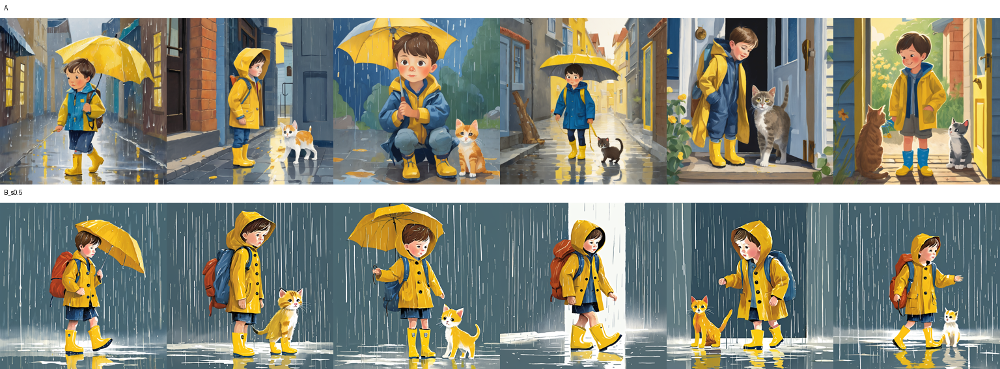

story 4《小狐狸第一次自己做生日蛋糕》 參考圖：


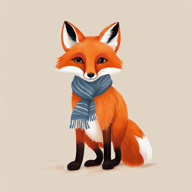

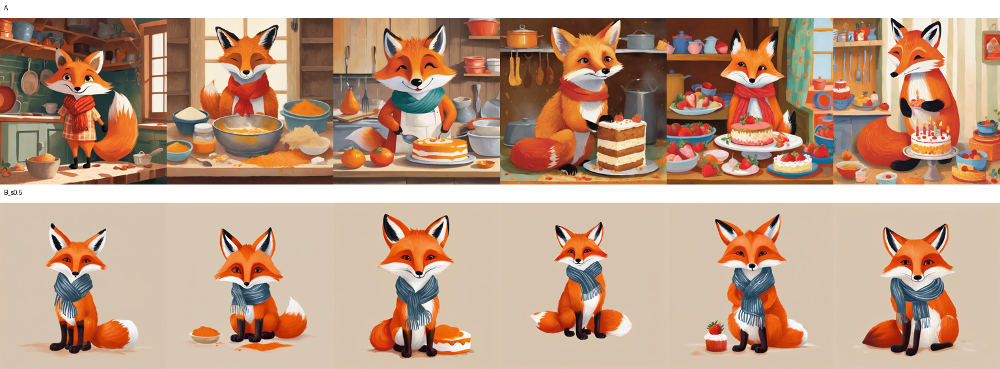

story 5《女孩和月亮的夜晚對話》 參考圖：


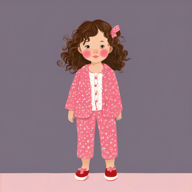

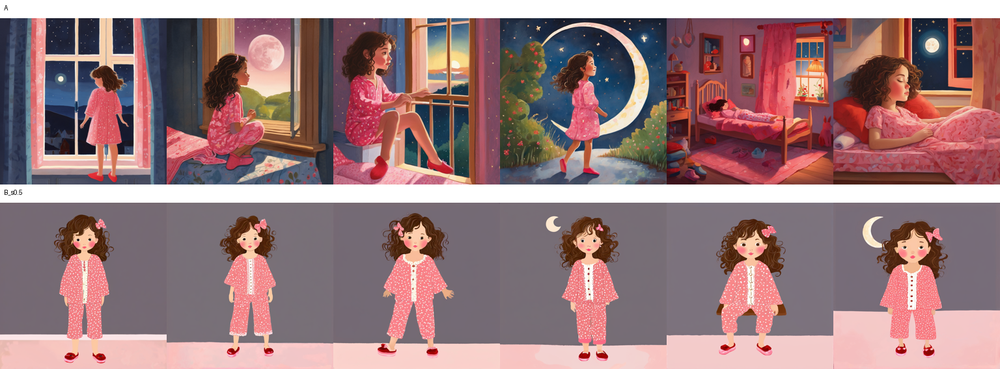

B_s0.5：已完成 30 格，平均每格 29.5 秒


In [11]:
BEST_SCALE = 0.5  # 依掃描結果修改
scheme = run_scheme_b(BEST_SCALE, STORIES)

for story_no in STORIES:
    compare(story_no, ["A", scheme])

secs = [json.loads(p.read_text(encoding="utf-8"))["seconds"]
        for p in (Path(OUT_ROOT) / scheme).glob("story_*/panel_*.json")]
print(f"{scheme}：已完成 {len(secs)} 格，平均每格 {sum(secs) / len(secs):.1f} 秒")